In [52]:
import geopandas as gpd
import matplotlib.pyplot as plt
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
from pathlib import Path
from scipy.fft import dct, idct
import numpy as np
from sklearn.neighbors import LocalOutlierFactor
from src.data_loader import load_reservoir_data


2026-11-03 13:34:23.545 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


# Loading and looking at shapefiles

In [3]:
# Load shapefiles
gdf_regions = gpd.read_file("../data/shapefiles/nve_region/NVE_Region.shp")
gdf_zones = gpd.read_file("../data/shapefiles/bidding_zones/biddingzones.shp")

print("NVE regions:")
print(gdf_regions.head())
print(gdf_regions.crs)

print("\nBidding zones:")
print(gdf_zones.head())
print(gdf_zones.crs)

NVE regions:
   OBJECTID REGION         REGIONNAVN POSTNUMMER   POSTSTED  \
0       1.0     RV        Region Vest       6801     FÃ¸rde   
1       2.0     RM  Region Midt-Norge       7030  Trondheim   
2       3.0     RN        Region Nord       8514     Narvik   
3       4.0    RÃ        Region Ãst       2307      Hamar   
4       5.0     RS        Region SÃ¸r       3103  TÃ¸nsberg   

               BESÃKSADR            ADRESSE  \
0       Naustdalsveien 1B        Postboks 53   
1  Abelsgate 9, Trondheim        Abelsgate 9   
2       Kongensgate 52-54  Kongensgate 52-54   
3           Vangsvegen 73      Postboks 4223   
4   Anton Jenssens gate 7      Postboks 2124   

                                            geometry  
0  POLYGON ((193105.76 6929797.839, 191705.75 692...  
1  POLYGON ((391250 7388620, 392270 7386790, 3937...  
2  POLYGON ((1109096.413 7844647.502, 1105115.343...  
3  POLYGON ((253748.22 6678130.91, 253645.58 6678...  
4  POLYGON ((253748.22 6678130.91, 253917.63

# Generate random coordinates

In [6]:
# Number of random points per region
K = 10

# NVE regions
points_nve = gdf_regions["geometry"].sample_points(
    size=K, random_state=42
)

# Electricity bidding zones
points_zones = gdf_zones["geometry"].sample_points(
    size=K, random_state=42
)

points_nve_wgs84 = points_nve.to_crs(epsg=4326)
points_zones_wgs84 = points_zones.to_crs(epsg=4326)

# Store coordinates by region
nve_coordinates = {}
zone_coordinates = {}

for idx, multipoint in points_nve_wgs84.items():
    region = gdf_regions.loc[idx, "REGION"]

    nve_coordinates[region] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        nve_coordinates[region].append((lon, lat))


for idx, multipoint in points_zones_wgs84.items():
    zone = gdf_zones.loc[idx, "budomr"]

    zone_coordinates[zone] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        zone_coordinates[zone].append((lon, lat))

print("NVE regions:")
for region, coordinates in nve_coordinates.items():
    print(region, len(coordinates), coordinates[:2])

print("\nBidding zones:")
for zone, coordinates in zone_coordinates.items():
    print(zone, len(coordinates), coordinates[:2])

print("NO3 coordinates:", len(zone_coordinates["NO 3"]))
print("First coordinate:", zone_coordinates["NO 3"][0])

NVE regions:
RV 10 [(6.744889030016078, 61.77937679971148), (8.10296168857449, 62.90988282724174)]
RM 10 [(12.278256451060217, 64.77623806958346), (12.072272210478358, 62.833752208426375)]
RN 10 [(19.366004320515948, 69.95052437031275), (15.577724456371026, 66.64984787939845)]
RÃ 10 [(7.653614356804278, 61.954229437327214), (11.43085954083096, 61.762216430955625)]
RS 10 [(9.409836560234448, 59.57973924599908), (7.232038377515692, 59.92120021901035)]

Bidding zones:
NO 1 10 [(11.670345245035588, 61.534228324972325), (10.936305892299593, 60.4291291451141)]
NO 2 10 [(6.274144429492754, 58.365982071313354), (5.103400693382628, 59.50988702488915)]
NO 3 10 [(11.990561650250058, 63.40858277494373), (11.445839720520302, 64.02966723467165)]
NO 4 10 [(22.570166893961755, 70.52472083029518), (29.61879934802335, 70.96016447632333)]
NO 5 10 [(6.192618146614597, 60.4189246121955), (4.965901852626455, 60.79693400356419)]
NO3 coordinates: 10
First coordinate: (11.990561650250058, 63.40858277494373)


# Set up Open-Meteo API Client

In [7]:
# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession(".cache", expire_after=3600)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# Select one random coordinate from NO3
lon, lat = zone_coordinates["NO 3"][0]

# Historical Weather API using ERA5 reanalysis
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lon,
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "hourly": ["temperature_2m", "precipitation"],
    "models": "era5",
    "timezone": "GMT"
}

responses = openmeteo.weather_api(url, params=params)

# Process first location
response = responses[0]

print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process hourly data
# Variable order must match the order requested in params
hourly = response.Hourly()

hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
hourly_precipitation = hourly.Variables(1).ValuesAsNumpy()

hourly_data = {
    "date": pd.date_range(
        start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
        end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=hourly.Interval()),
        inclusive="left"
    )
}

hourly_data["temperature_2m"] = hourly_temperature_2m
hourly_data["precipitation"] = hourly_precipitation

# Convert to Pandas DataFrame
df_weather = pd.DataFrame(data=hourly_data)

print("\nHourly data:")
display(df_weather.head())

# Check dimensions, missing values and descriptive statistics
print("\nShape:", df_weather.shape)
print("\nMissing values:")
print(df_weather.isna().sum())

display(df_weather.describe())

Coordinates: 63.5°N 12.0°E
Elevation: 685.0 m asl
Timezone difference to GMT+0: 0s

Hourly data:


,date,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-9.887,0.0
1,2024-01-01 01:00:00+00:00,-9.837,0.0
2,2024-01-01 02:00:00+00:00,-9.587,0.0
3,2024-01-01 03:00:00+00:00,-9.437,0.0
4,2024-01-01 04:00:00+00:00,-9.387,0.0



Shape: (168, 3)

Missing values:
date              0
temperature_2m    0
precipitation     0
dtype: int64


,temperature_2m,precipitation
count,168.000000,168.000000
mean,-13.409917,0.008333
std,2.905254,0.035320
min,-21.337000,0.000000
25%,-14.649500,0.000000
50%,-12.887000,0.000000
75%,-11.637000,0.000000
max,-6.737000,0.200000


# Creating reusable function
Making the api call a function which takes regional identifier and time interval as input. Also includes batching to reduce the HTTP overhead.

In [ ]:
from pathlib import Path

def download_weather(region, start_date, end_date):
    """
    Download hourly ERA5 weather data for all sampled coordinates
    in a region, saving each completed batch as a CSV file.
    """

    # Look up sampled coordinates for the selected region
    coordinates = zone_coordinates[region]
    url = "https://archive-api.open-meteo.com/v1/archive"

    batch_size = 10
    weather_data = []

    # Create folder for the selected region and time interval
    folder = Path("../data/weather") / f"{region.replace(' ', '')}_{start_date}_{end_date}test10"
    folder.mkdir(parents=True, exist_ok=True)

    # Loop through coordinates in batches of 10
    for i in range(0, len(coordinates), batch_size):

        batch = coordinates[i:i + batch_size]
        batch_file = folder / f"batch_{i:04d}.csv"

        # Load previously downloaded batches
        if batch_file.exists():
            print(f"Loading saved batch {i}")
            df = pd.read_csv(batch_file, parse_dates=["date"])
            weather_data.append(df)
            continue

        # Extract latitude and longitude lists
        longitudes = [lon for lon, lat in batch]
        latitudes = [lat for lon, lat in batch]

        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation"],
            "models": "era5",
            "timezone": "GMT"
        }

        # Download weather data for the batch
        responses = openmeteo.weather_api(url, params=params)

        batch_data = []

        # Process each location in the batch
        for j, response in enumerate(responses):

            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()

            # Construct DataFrame
            df = pd.DataFrame({
                "date": pd.date_range(
                    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=hourly.Interval()),
                    inclusive="left"
                ),
                "temperature_2m": temperature,
                "precipitation": precipitation
            })

            # Add location information
            lon, lat = batch[j]

            df["region"] = region
            df["location_id"] = i + j
            df["latitude"] = lat
            df["longitude"] = lon

            batch_data.append(df)

        # Combine data from the current batch
        df_batch = pd.concat(batch_data, ignore_index=True)

        # Save completed batch as CSV
        df_batch.to_csv(batch_file, index=False)

        weather_data.append(df_batch)

        print(
            f"Saved {min(i + batch_size, len(coordinates))} "
            f"/ {len(coordinates)} locations"
        )

    # Combine all batches into one DataFrame
    return pd.concat(weather_data, ignore_index=True)

In [14]:
df_weather = download_weather(
    "NO 3",
    "2024-01-01",
    "2024-12-31"
)

Saved 10 / 10 locations


In [15]:
print("Shape:", df_weather.shape)

print("Unique locations:")
print(df_weather["location_id"].nunique())

print("Date range:")
print(df_weather["date"].min())
print(df_weather["date"].max())

print("Missing values:")
print(df_weather.isna().sum())

display(df_weather.head())

Shape: (87840, 7)
Unique locations:
10
Date range:
2024-01-01 00:00:00+00:00
2024-12-31 23:00:00+00:00
Missing values:
date              0
temperature_2m    0
precipitation     0
region            0
location_id       0
latitude          0
longitude         0
dtype: int64


,date,temperature_2m,precipitation,region,location_id,latitude,longitude
0,2024-01-01 00:00:00+00:00,-9.887,0.0,NO 3,0,63.408583,11.990562
1,2024-01-01 01:00:00+00:00,-9.837,0.0,NO 3,0,63.408583,11.990562
2,2024-01-01 02:00:00+00:00,-9.587,0.0,NO 3,0,63.408583,11.990562
3,2024-01-01 03:00:00+00:00,-9.437,0.0,NO 3,0,63.408583,11.990562
4,2024-01-01 04:00:00+00:00,-9.387,0.0,NO 3,0,63.408583,11.990562


In [16]:
df_average = (
    df_weather
    .groupby("date")[["temperature_2m", "precipitation"]]
    .mean()
    .reset_index()
)

display(df_average.head())

,date,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-5.68355,0.0
1,2024-01-01 01:00:00+00:00,-5.73855,0.0
2,2024-01-01 02:00:00+00:00,-5.61855,0.0
3,2024-01-01 03:00:00+00:00,-5.54355,0.0
4,2024-01-01 04:00:00+00:00,-5.48355,0.0


# Same for 1000 points
Doing the exact same thing just for K = 1000 points.

In [17]:
# Number of random points per region
K = 1000

# NVE regions
points_nve = gdf_regions["geometry"].sample_points(
    size=K, random_state=42
)

# Electricity bidding zones
points_zones = gdf_zones["geometry"].sample_points(
    size=K, random_state=42
)

points_nve_wgs84 = points_nve.to_crs(epsg=4326)
points_zones_wgs84 = points_zones.to_crs(epsg=4326)

# Store coordinates by region
nve_coordinates = {}
zone_coordinates = {}

for idx, multipoint in points_nve_wgs84.items():
    region = gdf_regions.loc[idx, "REGION"]

    nve_coordinates[region] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        nve_coordinates[region].append((lon, lat))


for idx, multipoint in points_zones_wgs84.items():
    zone = gdf_zones.loc[idx, "budomr"]

    zone_coordinates[zone] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        zone_coordinates[zone].append((lon, lat))

print("NVE regions:")
for region, coordinates in nve_coordinates.items():
    print(region, len(coordinates), coordinates[:2])

print("\nBidding zones:")
for zone, coordinates in zone_coordinates.items():
    print(zone, len(coordinates), coordinates[:2])

print("NO3 coordinates:", len(zone_coordinates["NO 3"]))
print("First coordinate:", zone_coordinates["NO 3"][0])

NVE regions:
RV 1000 [(6.419148644681933, 60.04222571395746), (5.250840516619881, 62.57511551296885)]
RM 1000 [(9.602954018294431, 63.65155376162554), (9.770874943197038, 62.34158362100773)]
RN 1000 [(29.968740261154057, 70.5692207702202), (21.154915838284857, 70.67144182255329)]
RÃ 1000 [(9.814826090226477, 61.77679307320678), (10.90413753186709, 61.34442444551224)]
RS 1000 [(9.555077549525365, 58.81592269851404), (5.243891139512789, 59.060877823415744)]

Bidding zones:
NO 1 1000 [(12.054766924910693, 60.72851990770376), (10.141673251836874, 61.10018508824796)]
NO 2 1000 [(5.834334823011078, 60.10447814443446), (6.634705989002145, 58.80480982108946)]
NO 3 1000 [(9.328560324983709, 62.56745026518504), (8.442638438192015, 63.47212479506741)]
NO 4 1000 [(11.083971574794397, 66.11003434098366), (19.848629761246805, 69.18984259252156)]
NO 5 1000 [(7.84962486329475, 60.51033898017885), (8.083068679198028, 60.99279858693142)]
NO3 coordinates: 1000
First coordinate: (9.328560324983709, 62.56

In [ ]:
def download_weather(region, start_date, end_date):
    """
    Download hourly ERA5 weather data for all sampled coordinates
    in a region, saving each completed batch as a CSV file.
    """

    # Look up sampled coordinates for the selected region
    coordinates = zone_coordinates[region]
    url = "https://archive-api.open-meteo.com/v1/archive"

    batch_size = 10
    weather_data = []

    # Create folder for the selected region and time interval
    folder = Path("../data/weather") / f"{region.replace(' ', '')}_{start_date}_{end_date}"
    folder.mkdir(parents=True, exist_ok=True)

    # Loop through coordinates in batches of 10
    for i in range(0, len(coordinates), batch_size):

        batch = coordinates[i:i + batch_size]
        batch_file = folder / f"batch_{i:04d}.csv"

        # Load previously downloaded batches
        if batch_file.exists():
            print(f"Loading saved batch {i}")
            df = pd.read_csv(batch_file, parse_dates=["date"])
            weather_data.append(df)
            continue

        # Extract latitude and longitude lists
        longitudes = [lon for lon, lat in batch]
        latitudes = [lat for lon, lat in batch]

        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation"],
            "models": "era5",
            "timezone": "GMT"
        }

        # Download weather data for the batch
        responses = openmeteo.weather_api(url, params=params)

        batch_data = []

        # Process each location in the batch
        for j, response in enumerate(responses):

            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()

            # Construct DataFrame
            df = pd.DataFrame({
                "date": pd.date_range(
                    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=hourly.Interval()),
                    inclusive="left"
                ),
                "temperature_2m": temperature,
                "precipitation": precipitation
            })

            # Add location information
            lon, lat = batch[j]

            df["region"] = region
            df["location_id"] = i + j
            df["latitude"] = lat
            df["longitude"] = lon

            batch_data.append(df)

        # Combine data from the current batch
        df_batch = pd.concat(batch_data, ignore_index=True)

        # Save completed batch as CSV
        df_batch.to_csv(batch_file, index=False)

        weather_data.append(df_batch)

        print(
            f"Saved {min(i + batch_size, len(coordinates))} "
            f"/ {len(coordinates)} locations"
        )

    # Combine all batches into one DataFrame
    return pd.concat(weather_data, ignore_index=True)

In [19]:
df_weather = download_weather(
    "NO 3",
    "2024-01-01",
    "2024-12-31"
)

Saved 10 / 1000 locations
Saved 20 / 1000 locations
Saved 30 / 1000 locations
Saved 40 / 1000 locations
Saved 50 / 1000 locations
Saved 60 / 1000 locations
Saved 70 / 1000 locations
Saved 80 / 1000 locations
Saved 90 / 1000 locations
Saved 100 / 1000 locations
Saved 110 / 1000 locations
Saved 120 / 1000 locations
Saved 130 / 1000 locations
Saved 140 / 1000 locations
Saved 150 / 1000 locations
Saved 160 / 1000 locations
Saved 170 / 1000 locations
Saved 180 / 1000 locations
Saved 190 / 1000 locations
Saved 200 / 1000 locations
Saved 210 / 1000 locations
Saved 220 / 1000 locations
Saved 230 / 1000 locations
Saved 240 / 1000 locations
Saved 250 / 1000 locations
Saved 260 / 1000 locations
Saved 270 / 1000 locations
Saved 280 / 1000 locations
Saved 290 / 1000 locations
Saved 300 / 1000 locations
Saved 310 / 1000 locations
Saved 320 / 1000 locations
Saved 330 / 1000 locations
Saved 340 / 1000 locations
Saved 350 / 1000 locations
Saved 360 / 1000 locations
Saved 370 / 1000 locations
Saved 380 

# Saving regional hourly averages
Makes it easier to work with considering DCT/SPC and LOF.

In [21]:
df_average = (
    df_weather
    .groupby("date")[["temperature_2m", "precipitation"]]
    .mean()
    .reset_index()
)

df_average.to_csv(
    "../data/weather/NO3_2024_average.csv",
    index=False
)

display(df_average.head())

,date,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-3.573016,0.0041
1,2024-01-01 01:00:00+00:00,-3.710566,0.0033
2,2024-01-01 02:00:00+00:00,-3.685566,0.0032
3,2024-01-01 03:00:00+00:00,-3.718516,0.0032
4,2024-01-01 04:00:00+00:00,-3.668266,0.0026


In [22]:
print("Locations:", df_weather["location_id"].nunique())
print("Hourly observations:", len(df_average))
print("Missing values:")
print(df_average.isna().sum())

Locations: 1000
Hourly observations: 8784
Missing values:
date              0
temperature_2m    0
precipitation     0
dtype: int64


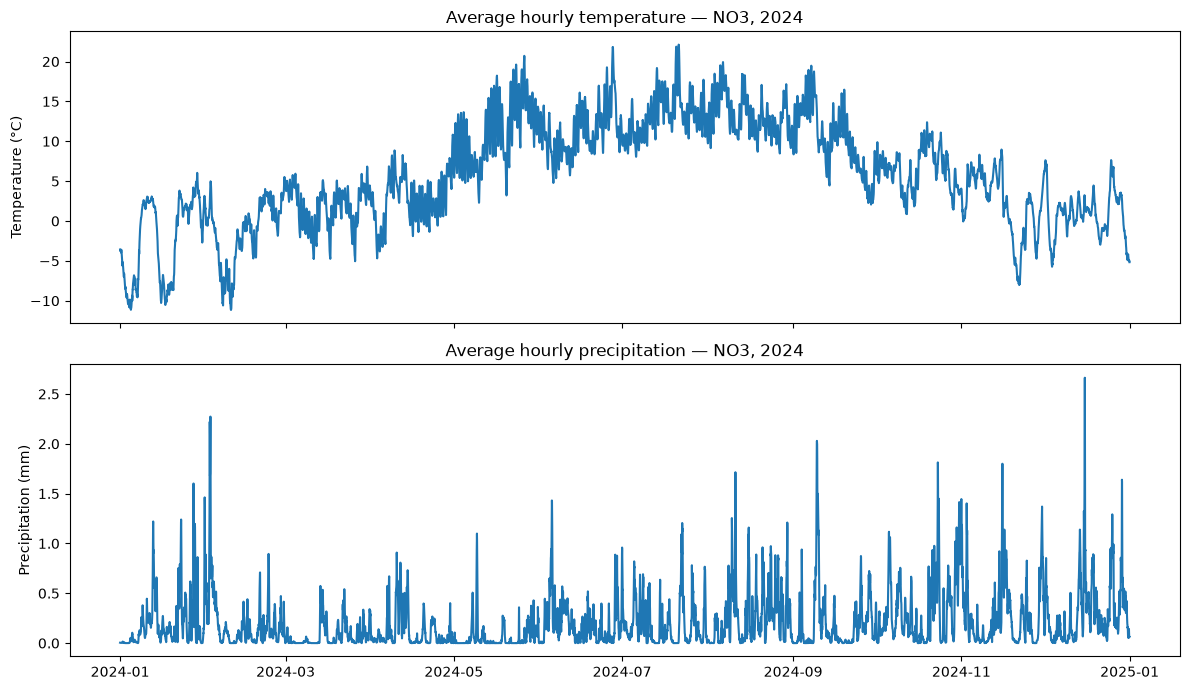

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(df_average["date"], df_average["temperature_2m"])
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_title("Average hourly temperature — NO3, 2024")

axes[1].plot(df_average["date"], df_average["precipitation"])
axes[1].set_ylabel("Precipitation (mm)")
axes[1].set_title("Average hourly precipitation — NO3, 2024")

plt.tight_layout()
plt.show()

# Converting to SATV using DCT
Converting the avg hrly precipitation to the SATV form using DCT

In [ ]:
# Extract average hourly precipitation
precipitation = df_average["precipitation"].values

# Apply Discrete Cosine Transform
fourier_signal = dct(precipitation, type=1, norm="forward")

# Remove low frequencies
cutoff = 30

filtered_fourier_signal = fourier_signal.copy()
filtered_fourier_signal[:cutoff] = 0

# Reconstruct the high-pass filtered signal
satv = idct(filtered_fourier_signal, type=1, norm="forward")

#

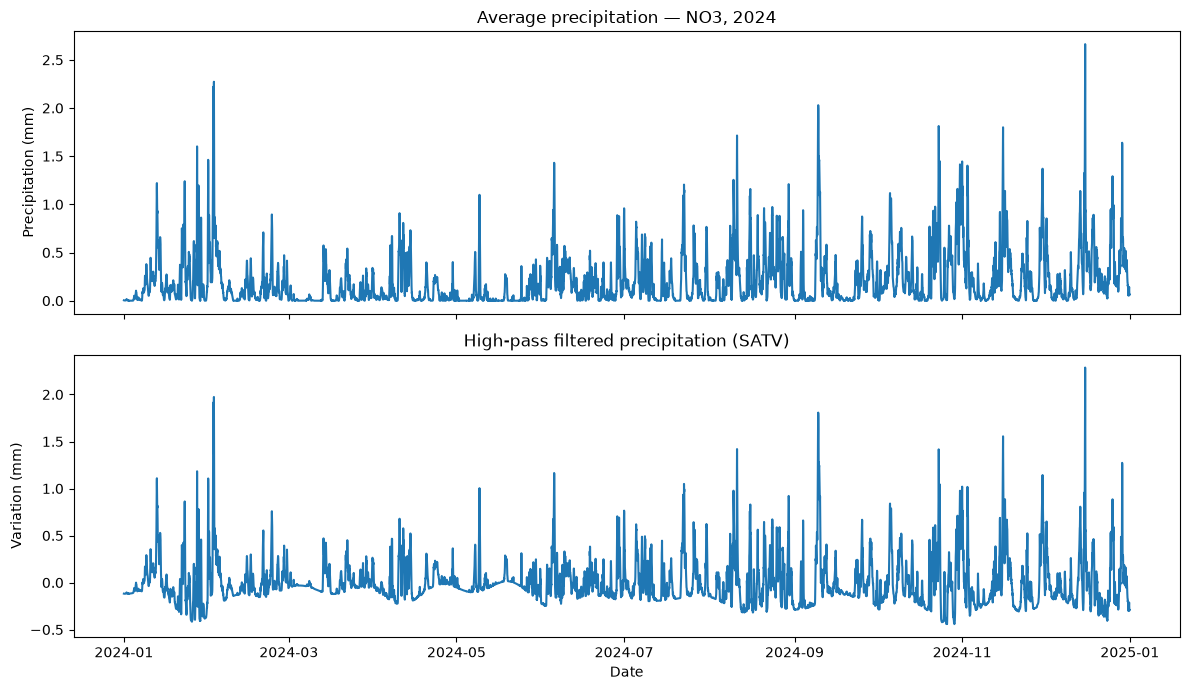

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(df_average["date"], precipitation)
axes[0].set_title("Average precipitation — NO3, 2024")
axes[0].set_ylabel("Precipitation (mm)")

axes[1].plot(df_average["date"], satv)
axes[1].set_title("High-pass filtered precipitation (SATV)")
axes[1].set_ylabel("Variation (mm)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

# Robust statistics
Using SPC with the SATV to find outliers

In [28]:
# Robust statistics based on SATV
median_satv = np.median(satv)

mad = np.median(np.abs(satv - median_satv))
robust_std = 1.4826 * mad

# SPC boundaries
n_std = 3

lower_bound = median_satv - n_std * robust_std
upper_bound = median_satv + n_std * robust_std

# Identify outliers
outliers = (satv < lower_bound) | (satv > upper_bound)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", outliers.sum())
print("Percentage of outliers:", 100 * outliers.mean())

Lower bound: -0.49739224
Upper bound: 0.38905185
Number of outliers: 613
Percentage of outliers: 6.978597449908926


# PLotting precipitation with outliers
Using SATV to plot the original values

In [29]:
# Reconstruct the removed low-frequency component
baseline = precipitation - satv

# Transform SPC boundaries back to precipitation scale
lower_curve = baseline + lower_bound
upper_curve = baseline + upper_bound

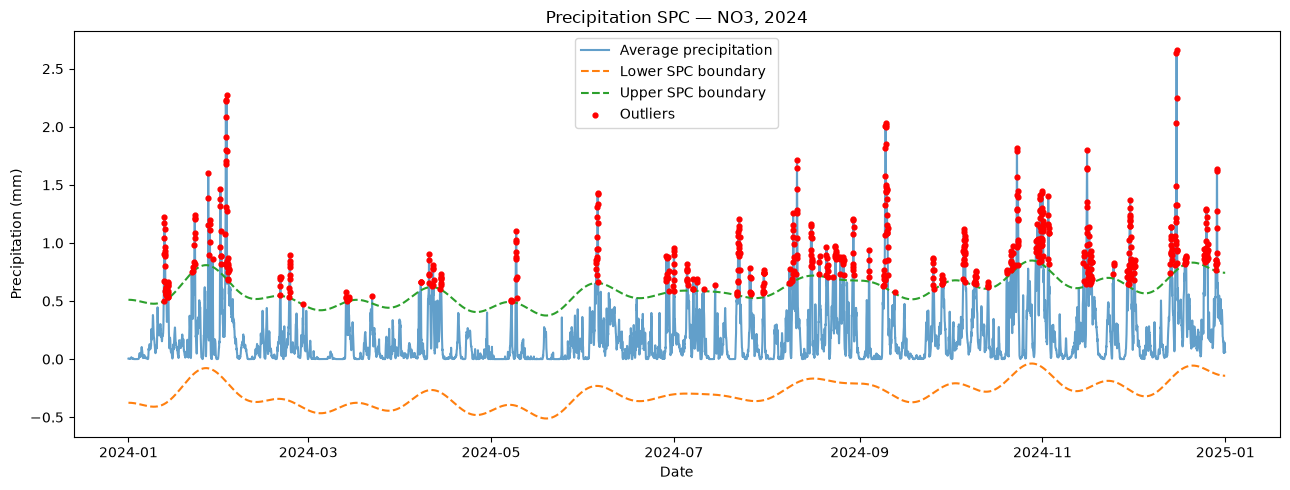

In [30]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    df_average["date"],
    precipitation,
    label="Average precipitation",
    alpha=0.7
)

ax.plot(
    df_average["date"],
    lower_curve,
    "--",
    label="Lower SPC boundary"
)

ax.plot(
    df_average["date"],
    upper_curve,
    "--",
    label="Upper SPC boundary"
)

ax.scatter(
    df_average.loc[outliers, "date"],
    precipitation[outliers],
    color="red",
    s=12,
    label="Outliers",
    zorder=3
)

ax.set_title("Precipitation SPC — NO3, 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Precipitation (mm)")
ax.legend()

plt.tight_layout()
plt.show()

In [31]:
print("Median SATV:", median_satv)
print("Robust standard deviation:", robust_std)
print("Outlier percentage:", round(100 * outliers.mean(), 2), "%")

Median SATV: -0.054170184
Robust standard deviation: 0.14774068
Outlier percentage: 6.98 %


# Wrapping in a function

In [33]:
def precipitation_spc(df, cutoff=30, n_std=3):
    """
    Detect precipitation outliers using DCT high-pass filtering
    and robust Statistical Process Control (SPC).

    Returns the plot and a summary of outliers.
    """

    # Extract precipitation data
    precipitation = df["precipitation"].to_numpy()
    dates = df["date"]

    # DCT high-pass filtering
    fourier_signal = dct(precipitation, type=1, norm="forward")

    filtered_signal = fourier_signal.copy()
    filtered_signal[:cutoff] = 0

    satv = idct(filtered_signal, type=1, norm="forward")

    # Robust statistics based on SATV
    median_satv = np.median(satv)
    mad = np.median(np.abs(satv - median_satv))
    robust_std = 1.4826 * mad

    # SPC boundaries
    lower_bound = median_satv - n_std * robust_std
    upper_bound = median_satv + n_std * robust_std

    # Identify outliers
    upper_outliers = satv > upper_bound
    lower_outliers = satv < lower_bound
    outliers = upper_outliers | lower_outliers

    # Transform boundaries back to precipitation scale
    baseline = precipitation - satv

    lower_curve = baseline + lower_bound
    upper_curve = baseline + upper_bound

    # Plot original precipitation and SPC boundaries
    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(dates, precipitation, label="Average precipitation", alpha=0.7)
    ax.plot(dates, lower_curve, "--", label="Lower SPC boundary")
    ax.plot(dates, upper_curve, "--", label="Upper SPC boundary")

    ax.scatter(
        dates[outliers],
        precipitation[outliers],
        color="red",
        s=12,
        label="Outliers",
        zorder=3
    )

    ax.set_title("Precipitation SPC — NO3, 2024")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm)")
    ax.legend()

    plt.tight_layout()

    # Outlier summary
    summary = {
        "total_observations": len(precipitation),
        "total_outliers": int(outliers.sum()),
        "upper_outliers": int(upper_outliers.sum()),
        "lower_outliers": int(lower_outliers.sum()),
        "outlier_percentage": round(100 * outliers.mean(), 2),
        "median_satv": float(median_satv),
        "robust_std": float(robust_std)
    }

    return fig, summary

# Testing the function

In [37]:
fig, summary = precipitation_spc(df_average)

assert isinstance(fig, plt.Figure)
assert summary["total_observations"] == len(df_average)
assert summary["total_outliers"] == (
    summary["upper_outliers"] + summary["lower_outliers"]
)
assert 0 <= summary["outlier_percentage"] <= 100

print("All tests passed!")
plt.close(fig)

All tests passed!


# LOF Temperature
Interpretation of LOF: it identifies anomalies based on the local density of temperature, but does not account for time or seasonality. Therefore anomalies occurs at seamingly normal temperatures. The method identifies statistically unusual values, rather than temperatures that are unusual for the season. 

In [40]:
# Extract temperature data
temperature = df_average["temperature_2m"].to_numpy()

# Reshape to a 2D array (required by scikit-learn)
X = temperature.reshape(-1, 1)

# Apply Local Outlier Factor
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01
)

labels = lof.fit_predict(X)

# LOF returns -1 for outliers and 1 for inliers
anomalies = labels == -1

print("Total observations:", len(temperature))
print("Number of anomalies:", anomalies.sum())
print("Anomaly percentage:", round(100 * anomalies.mean(), 2), "%")

Total observations: 8784
Number of anomalies: 88
Anomaly percentage: 1.0 %


# Plot temperature

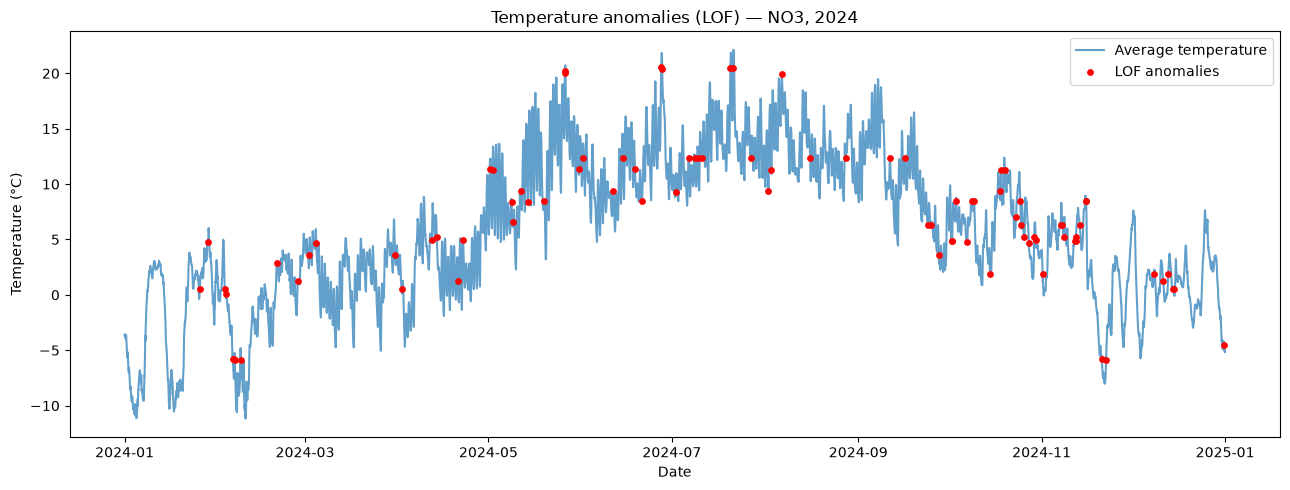

In [41]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    df_average["date"],
    temperature,
    label="Average temperature",
    alpha=0.7
)

ax.scatter(
    df_average.loc[anomalies, "date"],
    temperature[anomalies],
    color="red",
    s=15,
    label="LOF anomalies",
    zorder=3
)

ax.set_title("Temperature anomalies (LOF) — NO3, 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()

plt.tight_layout()
plt.show()

# LOF Function

In [42]:
def temperature_lof(df, contamination=0.01):
    """
    Detect temperature anomalies using Local Outlier Factor (LOF).

    Returns the plot and a summary of detected anomalies.
    """

    # Extract temperature data
    temperature = df["temperature_2m"].to_numpy()
    dates = df["date"]

    # Reshape data for scikit-learn
    X = temperature.reshape(-1, 1)

    # Apply Local Outlier Factor
    lof = LocalOutlierFactor(
        n_neighbors=20,
        contamination=contamination
    )

    labels = lof.fit_predict(X)

    # Identify anomalies
    anomalies = labels == -1

    # Plot temperature and anomalies
    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        dates,
        temperature,
        label="Average temperature",
        alpha=0.7
    )

    ax.scatter(
        dates[anomalies],
        temperature[anomalies],
        color="red",
        s=15,
        label="LOF anomalies",
        zorder=3
    )

    ax.set_title("Temperature anomalies (LOF) — NO3, 2024")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()

    plt.tight_layout()

    # Anomaly summary
    summary = {
        "total_observations": len(temperature),
        "total_anomalies": int(anomalies.sum()),
        "anomaly_percentage": round(100 * anomalies.mean(), 2),
        "mean_temperature": float(np.mean(temperature)),
        "mean_anomaly_temperature": float(np.mean(temperature[anomalies]))
            if anomalies.any() else None,
        "min_anomaly_temperature": float(np.min(temperature[anomalies]))
            if anomalies.any() else None,
        "max_anomaly_temperature": float(np.max(temperature[anomalies]))
            if anomalies.any() else None
    }

    return fig, summary

{'total_observations': 8784,
 'total_anomalies': 88,
 'anomaly_percentage': np.float64(1.0),
 'mean_temperature': 5.799082279205322,
 'mean_anomaly_temperature': 6.903907299041748,
 'min_anomaly_temperature': -5.8913655281066895,
 'max_anomaly_temperature': 20.603134155273438}

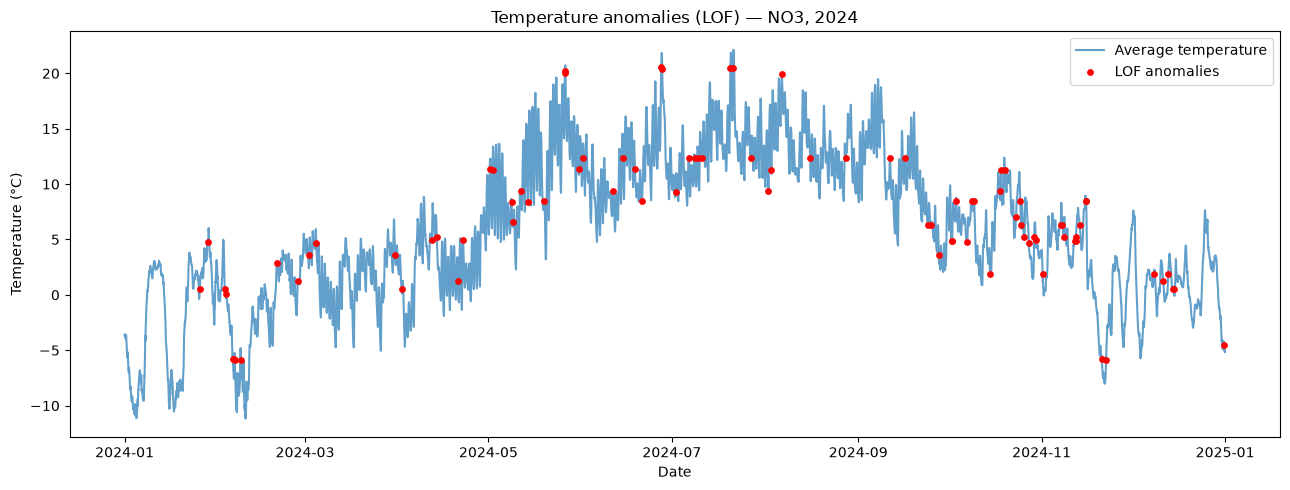

In [45]:
fig, summary = temperature_lof(df_average)

display(summary)
plt.show()

# Testing LOF function


In [46]:
# Test default parameters
fig, summary = temperature_lof(df_average)

assert isinstance(fig, plt.Figure)

assert summary["total_observations"] == len(df_average)

assert 0 <= summary["anomaly_percentage"] <= 100

assert summary["total_anomalies"] <= summary["total_observations"]

assert abs(summary["anomaly_percentage"] - 1.0) < 0.2

plt.close(fig)

# Test different contamination values
fig_1, summary_1 = temperature_lof(df_average, contamination=0.01)
fig_5, summary_5 = temperature_lof(df_average, contamination=0.05)

assert summary_5["total_anomalies"] > summary_1["total_anomalies"]

plt.close(fig_1)
plt.close(fig_5)

print("All LOF tests passed!")

All LOF tests passed!


In [53]:
df_reservoir = load_reservoir_data()

display(df_reservoir.head())

2026-11-03 13:35:07.524 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-03 13:35:07.525 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,date,area_type,area_id,iso_year,iso_week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_prev_week,fill_level_change
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
9688,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643
11182,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
14511,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349


In [ ]:
df_no3 = df_reservoir[
    (df_reservoir["area_type"] == "EL") &
    (df_reservoir["area_id"] == "NO3")
].copy()

df_no3["date"] = pd.to_datetime(df_no3["date"])
df_no3 = df_no3.sort_values("date")

# Set date as index
fill_level = df_no3.set_index("date")["fill_level"]

display(fill_level.head())

[1 3 2 4 5]


# AI Usage

# Log